# 04 – Explainability: why did the model raise this alarm?

**Stage 8 of the project.** A technician will not trust "risk 0.97" without a reason.

**SHAP** splits every prediction into contributions per feature:

> prediction = average prediction + contribution of feature 1 + contribution of feature 2 + …

Positive contribution → pushes towards failure. Negative → towards normal.
Production code: `src/explain.py`.

In [1]:
import sys
sys.path.append("..")          # lets Python find the src folder
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import joblib
from src.data import load_prepared, split_train_test
from src.explain import failure_shap_values

%matplotlib inline
from src.plotting import set_style
set_style()

bundle = joblib.load("../models/failure_model.joblib")
model, features, threshold = bundle["model"], bundle["features"], bundle["threshold"]
_, test = split_train_test(load_prepared())
X = test[features]
values, base = failure_shap_values(model, X)
print("Baseline (average) risk score:", round(base, 2))

Baseline (average) risk score: 0.5


## 1. What matters overall?

In [2]:
pd.Series(np.abs(values).mean(axis=0), index=features).sort_values(ascending=False).round(3)

speed_rpm          0.104
power_w            0.101
torque_nm          0.083
strain_nm_min      0.071
temp_diff_k        0.066
tool_wear_min      0.062
air_temp_k         0.028
process_temp_k     0.016
product_quality    0.008
dtype: float64

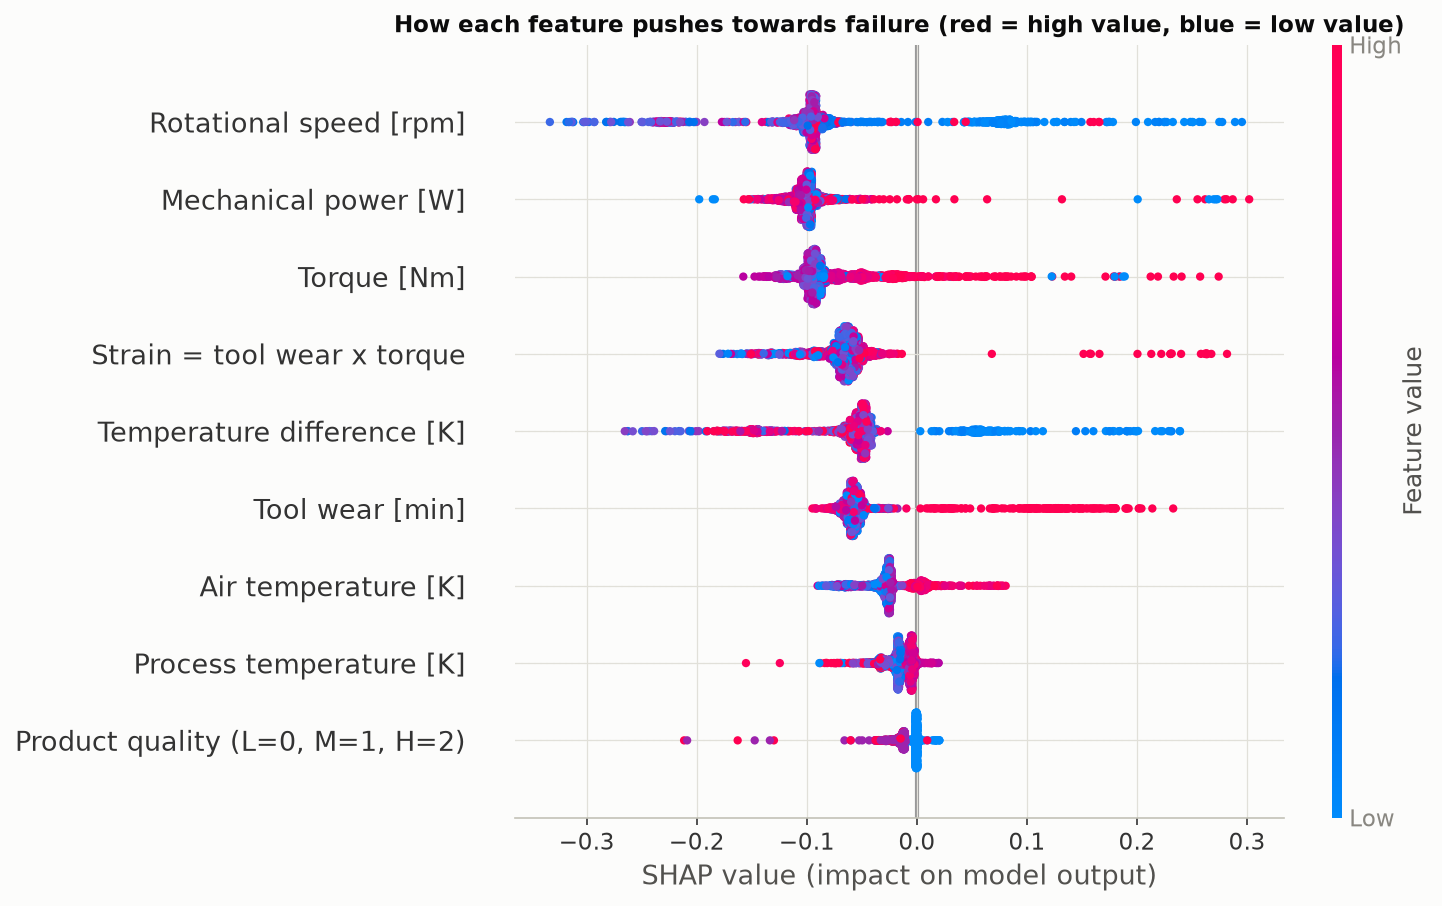

In [3]:
from IPython.display import Image
Image('../reports/figures/shap_beeswarm.png')

Speed, power, torque, strain and temperature difference dominate – exactly the variables behind the
four failure mechanisms found in the EDA. The model learned the physics, not a coincidence.
Product quality matters little on its own: its effect runs through the strain limit.

## 2. One alarm, explained

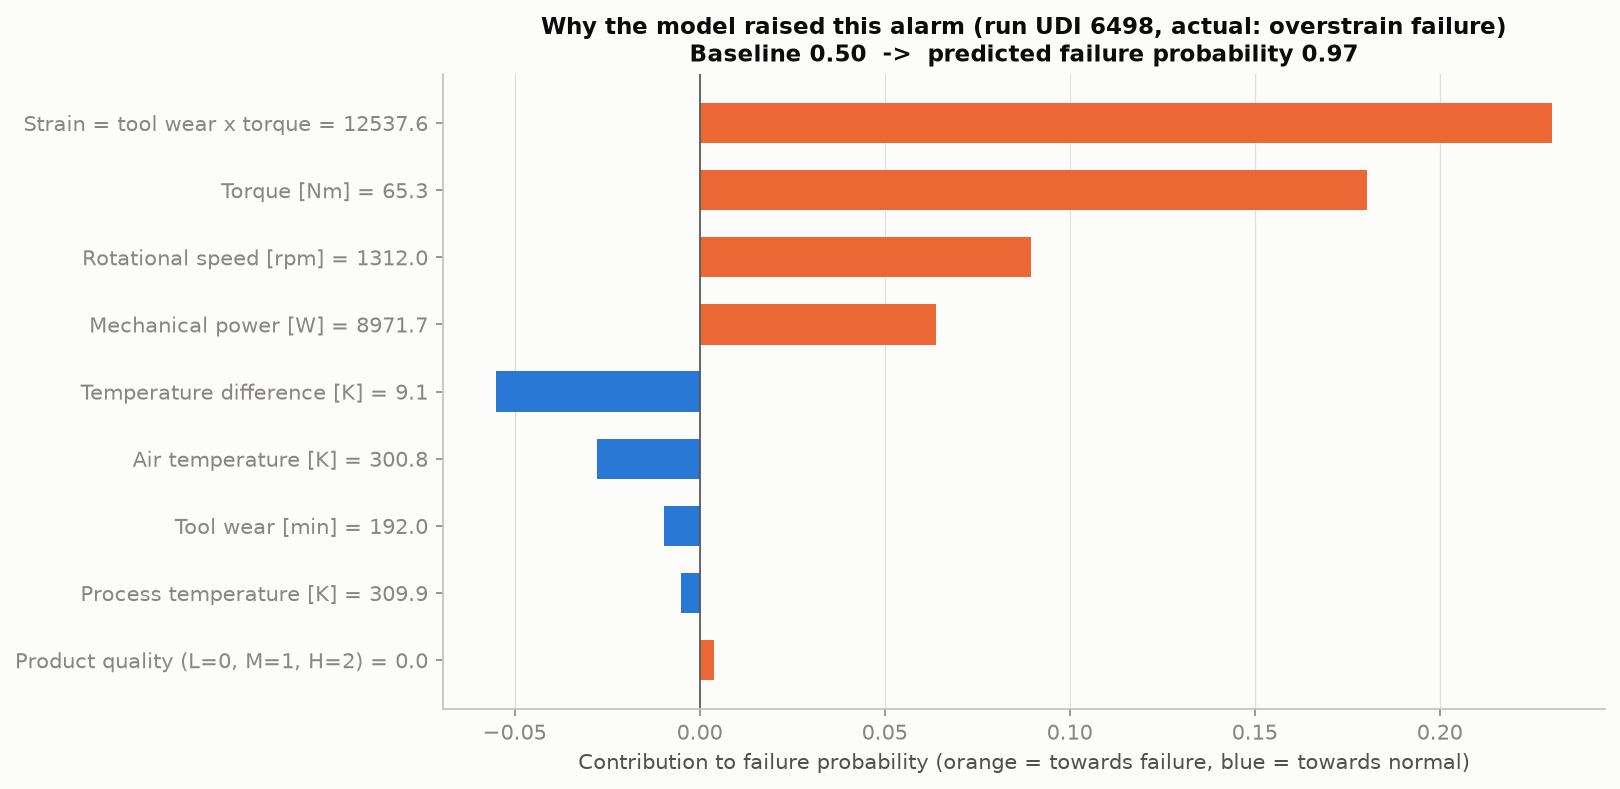

In [4]:
Image('../reports/figures/shap_example_alarm.png')

High **strain** and high **torque** push this run towards failure – the overstrain mechanism.
A technician reading this knows what to check: the tool and the load.

## 3. One miss, explained

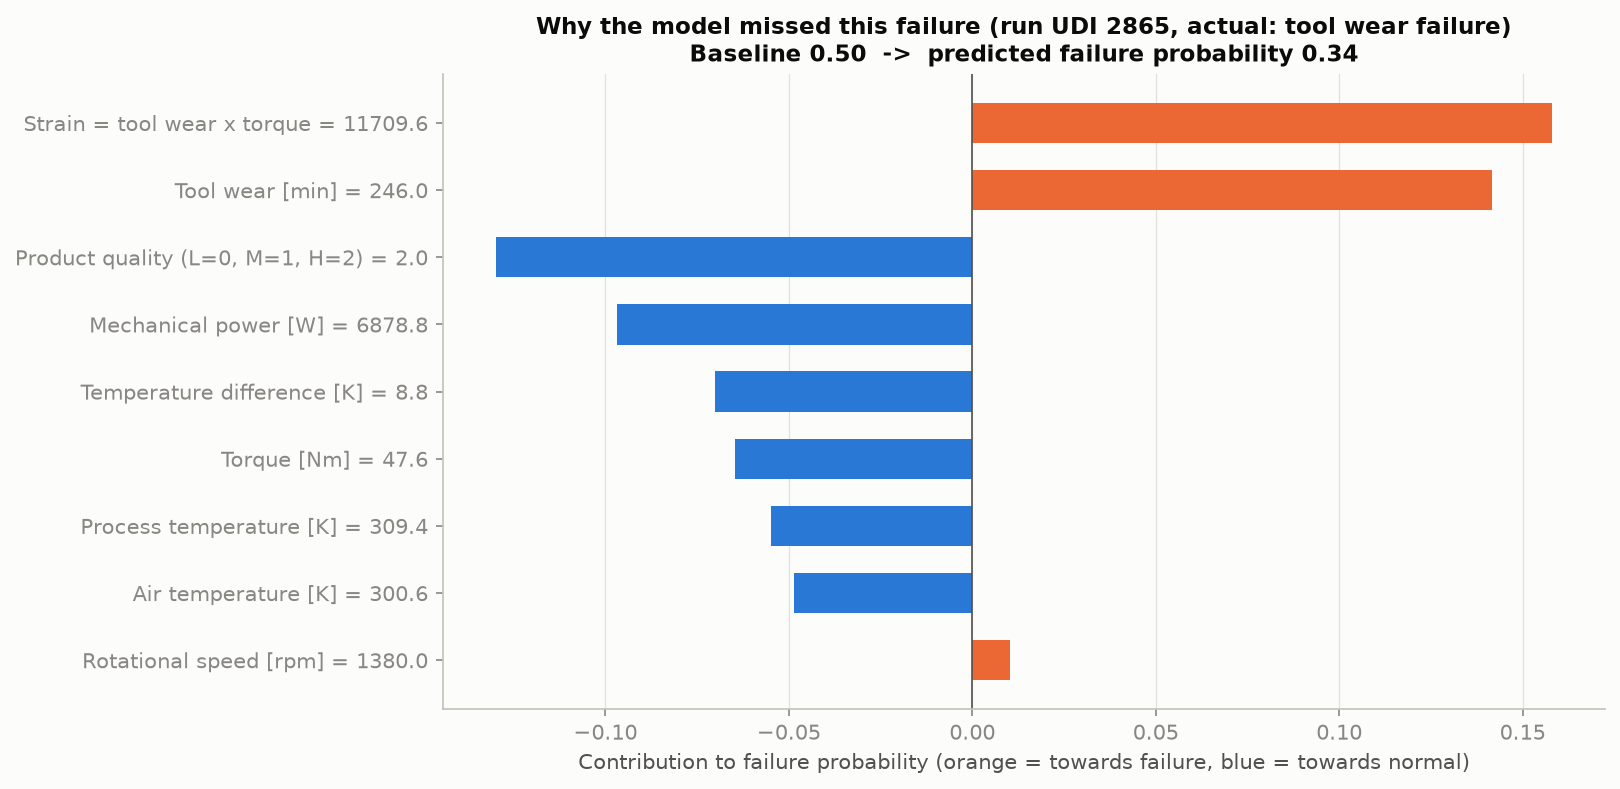

In [5]:
Image('../reports/figures/shap_example_missed.png')

High tool wear and strain push towards failure, but not past the alarm threshold. Many runs with similar
tool wear *don't* fail, because tool-wear failures happen at a random moment. SHAP shows the model's
reasoning was sensible – the limit is in the data, which supports the recommendation of planned tool changes.